# Kernel Taylor diagrams: a synthetic example

A **Taylor diagram** compares candidate datasets with a reference in one polar plot, where each
candidate is one point.

* Its **distance from the origin** is its standard deviation, relative to the reference.
* Its **angle** is its correlation with the reference.
* Its **distance to the reference point** is the error between the two (the RMSE).

All three come from one way of comparing two datasets, an *inner product*, and changing it
changes what the diagram measures. The kernel diagrams have one parameter, the kernel width
$\sigma$, the distance below which two points count as similar.

| Diagram        | Compares                                  | Insensitive to                     |
|----------------|-------------------------------------------|------------------------------------|
| Classic        | the samples pair by pair, linearly        | how the error spreads over samples |
| Kernel classic | paired samples, with a tolerance $\sigma$ | the size of errors beyond $\sigma$ |
| Kernel HSIC    | the internal structure of each dataset    | rotations, reflections and shifts  |
| Kernel MMD     | the distributions of the points           | the order of the samples           |

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
# useful on linux to avoid numpy multithreading

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
#from sklearn.metrics import pairwise_distances
#from sklearn.metrics.pairwise import rbf_kernel
import sklearn

# Kernel Taylor Diagram utilities (local modules, run from the repository root)
from src.taylor_diagram_plot import TaylorDiagramPlot  # handles diagram visualisation
import src.kernel_taylor_diagram as ktd

## Synthetic data

The reference is a noise-free line of 500 points. The sample index runs along it like time.
Seven candidates are compared with it. Five of them have, by construction, the same classic
standard deviation, correlation and RMSE, but a different structure:

| Candidate | What it is |
|---|---|
| Noisy reference | the line plus Gaussian noise (0.25) |
| Noise burst | the line with weak noise (0.13), and strong noise (0.93) on 25 samples in the middle |
| Dense core | the points crowd in the middle of the line |
| U-shaped curve | the line bent into a parabola, with noise (0.15) |
| Rotated noisy reference | the noisy line rotated by 60 degrees |
| Clustered data | the points crowd at the two ends of the line: two clusters |
| Shuffled reference | the reference with its samples in random order |

Each dataset is an array of shape [500, 2], the candidates are dicts with a `name`, a `color`
and the data `ts`.

We build mean-centered datasets using `generate_datasets` and then plot them. This is the contents of `generate_synthetic_datasets.py`:

In [2]:
def generate_noise_burst_data(t, e, c=0.97, sigma=0.13, burst_sigma=0.93, burst_fraction=0.05,
                              seed=4):
    """
    Generate 'Noise burst': the line, scaled by c, with Gaussian noise everywhere, much stronger
    during a short burst in the middle of the time, covering a fraction burst_fraction of the
    samples. Most of the error of this candidate is concentrated in the burst. This function
    has its own random number generator, so its output depends only on seed and not on any
    other random draw.

    t: positions along the line, in increasing order
    e: unit vector of the direction of the line, x(t) = t * e
    c: scale of the line
    sigma: noise std (per coordinate) outside the burst, the background
    burst_sigma: noise std (per coordinate) during the burst
    burst_fraction: fraction of the samples, in the middle of the time, that form the burst
    seed: seed of the random number generator that draws the noise

    Returns the data, [n, 2] (not mean-centred).
    """
    rng = np.random.default_rng(seed)
    n = len(t)
    x = np.outer(t, e)                              # the noise-free line

    k = int(round(burst_fraction * n))              # number of samples in the burst
    if k < 2 or k > n - 2:
        raise ValueError("burst_fraction must leave at least 2 samples in the burst and outside.")
    start = (n - k) // 2                            # the burst is in the middle of the time
    burst = np.zeros(n, dtype=bool)
    burst[start:start + k] = True
    W = rng.normal(size=(n, 2))
    N = np.zeros((n, 2))
    for region, level in ((~burst, sigma), (burst, burst_sigma)):
        N[region] = level * (W[region] / W[region].std(axis=0))   # std exactly level; mean kept

    return c * x + N

def generate_warped_line_data(t, e, c=1.45, s=0.14, warp_power=2.5, seed=5):
    """
    Generate 'Warped line': the line with its points redistributed along it, plus Gaussian
    noise. With warp_power > 1 the points are dense in the middle and sparse at the ends, with
    warp_power < 1 they are dense at the ends and sparse in the middle; the order along the
    line is kept. This function has its own random number generator, so its output depends only
    on seed and not on any other random draw.

    t: positions along the line, in increasing order, in [-a, a]
    e: unit vector of the direction of the line, x(t) = t * e
    c: scale of the warped line
    s: noise std (per coordinate)
    warp_power: exponent p of the warp w(t) = a * sign(t) * |t / a|^p; p = 1 is the line
    seed: seed of the random number generator that draws the noise

    Returns the data, [n, 2] (not mean-centred).
    """
    rng = np.random.default_rng(seed)
    n = len(t)
    a = np.abs(t).max()                             # half-length of the line
    W = np.outer(a * np.sign(t) * np.abs(t / a)**warp_power, e)
    N = rng.normal(size=(n, 2))
    N = N / N.std(axis=0)                           # unit sample std; the mean is kept

    return c * W + s * N

def generate_u_curve_data(t, e, c=0.98, h=0.96, sigma=0.15, seed=6):
    """
    Generate 'U-shaped curve': the line bent into a U, a parabola whose ends both bend to the
    same side of the line, plus Gaussian noise,
        Y(t) = c * x(t) + h * (t / a)^2 * n + sigma * zeta,
    with x(t) = t * e the line, n its normal and zeta unit noise. This function has its own
    random number generator, so its output depends only on seed.

    t: positions along the line, in increasing order, in [-a, a]
    e: unit vector of the direction of the line
    c: scale of the line
    h: depth of the U: the ends are displaced by h along the normal, the middle not at all
    sigma: noise std (per coordinate)
    seed: seed of the random number generator that draws the noise

    Returns the data, [n, 2] (not mean-centred).
    """
    rng = np.random.default_rng(seed)
    a = np.abs(t).max()
    normal = np.array([-e[1], e[0]])                # normal of the line
    U = np.outer(t, e)
    V = np.outer((t / a)**2, normal)
    N = rng.normal(size=U.shape)
    W = sigma * (N / N.std(axis=0))                 # noise std exactly sigma; the mean is kept

    return c * U + h * V + W

def generate_datasets():
    """
    Generate the reference dataset and the candidate datasets, all mean-centred.

    Returns X (the reference, [n, 2]), and a list of candidate dicts with a 'name', a 'color' and
    the data 'ts' ([n, 2]).
    """
    # --- Common parameters ---
    n = 500                 # number of samples
    noise = 0.25            # noise std sigma (per coordinate) of the noisy candidates
    seed = 2                # seed of the random number generator
    np.random.seed(seed)

    # --- Line as a function of the parameter t ---
    # x(t) = t * e, t in [-a, a], a = sqrt(2), with e the direction of the line x2 = -x1
    a = np.sqrt(2.)
    t = np.linspace(-a, a, n)
    e = np.array([-1., 1.]) / np.sqrt(2.)               # direction of the line
    line = np.outer(t, e)

    # --- Reference: the ground truth, the noise-free line ---
    X = line

    datasets = []

    # --- Candidate 1: Noisy ground truth ---
    # The ground truth with Gaussian noise
    Y_noise = line + noise * np.random.normal(size=line.shape)
    datasets.append({'color': 'tab:red', 'name': 'Noisy reference', 'ts': Y_noise})

    # The order of 'Shuffled data' is drawn here, right after 'Noisy ground truth', but the
    # dataset is added at the end of the list: 'Shuffled data' is always the last candidate
    shuffle_order = np.random.permutation(n)

    # --- Candidate 2: Noise burst ---
    # The line, scaled, with a weak background noise and a strong noise during a short burst in
    # the middle of the time, made by a separate function with its own random number
    # generator. Its parameters are the defaults of the function.
    Y_burst = generate_noise_burst_data(t, e)
    datasets.append({'color': 'tab:green', 'name': 'Noise burst', 'ts': Y_burst})

    # --- Candidate 3: Dense core ---
    # The line with its points dense in the middle and stretched at the ends, plus noise, made
    # by a separate function with its own random number generator. Its parameters are the
    # defaults of the function.
    Y_core = generate_warped_line_data(t, e)
    datasets.append({'color': 'tab:pink', 'name': 'Dense core', 'ts': Y_core})

    # --- Candidate 4: U-shaped curve ---
    # The line bent into a U, plus noise, made by a separate function with its own random
    # number generator. Its parameters are the defaults of the function.
    Y_u_curve = generate_u_curve_data(t, e)
    datasets.append({'color': 'tab:cyan', 'name': 'U-shaped curve', 'ts': Y_u_curve})

    # --- Candidate 5: Rotated line ---
    # The ground truth rotated by angle degrees (counterclockwise) around its centre, with
    # noise of the same level as the noisy ground truth
    angle = 60.
    phi = np.deg2rad(angle)
    R = np.array([[np.cos(phi), -np.sin(phi)],
                  [np.sin(phi), np.cos(phi)]])
    datasets.append({'color': 'tab:purple', 'name': 'Rotated noisy reference',
                     'ts': line @ R.T + noise * np.random.normal(size=line.shape)})

    # --- Candidate 6: Clustered data ---
    # The warp the other way round, with an exponent below 1: the points are dense at the two
    # ends of the line, which makes two clusters, and sparse in the middle, plus noise. Same
    # function as candidate 3, with its own parameters and seed. The smaller the exponent, the
    # stronger the clusters, but the less the warp correlates with the line: it must stay above
    # about 0.15 for noise 0.25.
    Y_clustered = generate_warped_line_data(t, e, c=0.73, s=0.11, warp_power=0.2, seed=9)
    datasets.append({'color': 'tab:blue', 'name': 'Clustered data', 'ts': Y_clustered})

    # --- Candidate 7: Shuffled data ---
    # The noisy ground truth with samples reordered randomly: exactly the same set of points
    # (so the same distribution), but the sample-to-sample correspondence is lost
    datasets.append({'color': 'tab:orange', 'name': 'Shuffled reference',
                     'ts': X[shuffle_order, :]})

    # --- Preprocessing: mean-centre the reference and all candidates ---
    # (the mean of each dataset is subtracted; the standard deviation is left unchanged)
    X = X - X.mean(axis=0)
    for dataset in datasets:
        dataset['ts'] = dataset['ts'] - dataset['ts'].mean(axis=0)

    return X, datasets

In [3]:
def plot_datasets(X, datasets, save_as=None):
    """Scatter plot of the reference and of each candidate, with the reference line in gray."""
    panels = [('Reference (ground truth)', X, 'black')] + [(d['name'], d['ts'], d['color'])
                                                           for d in datasets]
    ncols = int(np.ceil(len(panels) / 2))
    fig, axs = plt.subplots(2, ncols, figsize=(3 * ncols, 6), sharex=True, sharey=True,
                            squeeze=False)
    axs = axs.flatten()
    for ax in axs[len(panels):]:
        ax.axis('off')
    for i, (ax, (name, A, color)) in enumerate(zip(axs, panels)):
        if i > 0:
            ax.plot(X[:, 0], X[:, 1], '-', color='gray', lw=1)
        ax.plot(A[:, 0], A[:, 1], '.', color=color, ms=3)
        ax.set_title(name)
        ax.set_xlim(-2, 2)
        ax.set_ylim(-2, 2)
        ax.grid(True)
    fig.tight_layout()
    if save_as:
        fig.savefig(save_as, dpi=150, bbox_inches='tight', transparent=True)
    plt.show()

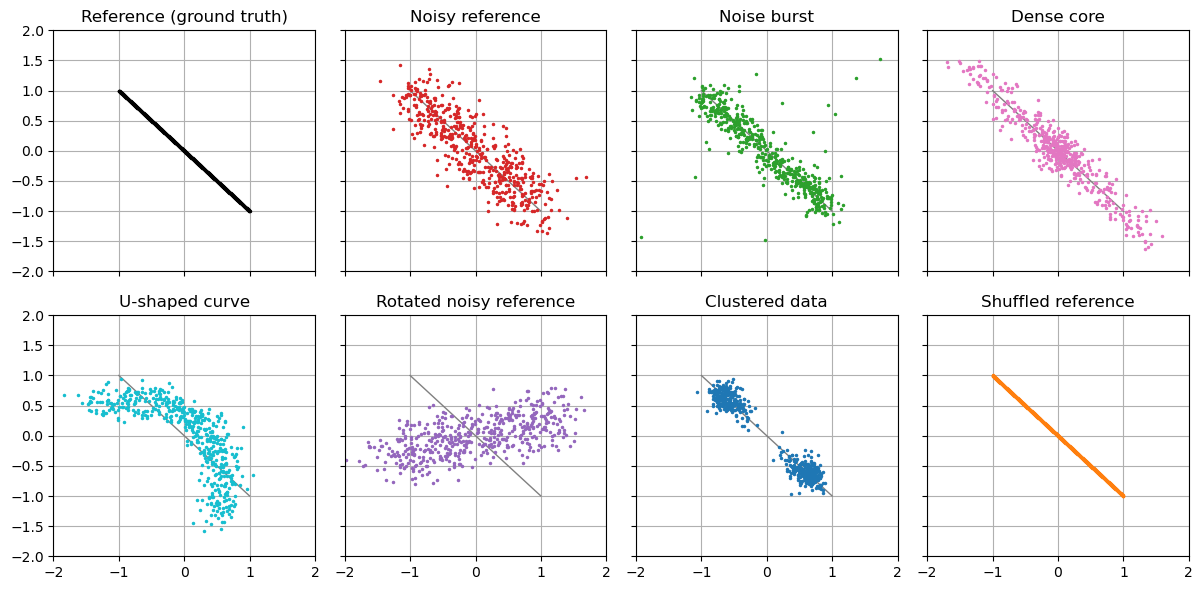

In [4]:
X, datasets = generate_datasets()
plot_datasets(X, datasets, save_as='demo1_data.png')

The shuffled reference looks exactly like the reference. It is the same set of points, only
their order differs.

## Kernels and centered kernel matrices

A **kernel** $k(x, y)$ is used to generalize the dot product of two points (vectors) $x$ and
$y$. The classic dot product is given by the linear kernel $k(x, y) = x^\top y$.

The **RBF kernel**

$$k(x, y) = \exp\left(-\frac{\lVert x - y\rVert^2}{2\sigma^2}\right)$$

depends only on the distance between the points: 1 for the same point, close to 0 for points
much further apart than $\sigma$. There exists a feature mapping $\phi$ into a reproducing
kernel Hilbert space (RKHS) that turns it into a dot product,
$k(x, y) = \langle\phi(x), \phi(y)\rangle$. The RKHS has infinitely many dimensions but is never
built explicitly, because the kernel gives the dot product  values directly. This dot product thus measures the similarity
of $x$ and $y$.

The **kernel matrix** $K$ of a dataset holds the kernel value of every pair of its samples,
$K_{ij} = k(x_i, x_j)$. The **mean-centered kernel** measures the similarity of two samples
relative to the dataset as a whole: the mean feature vector $\bar\phi$ is subtracted from every
feature vector, $\tilde K_{ij} = \langle\phi(x_i) - \bar\phi, \phi(x_j) - \bar\phi\rangle$.
Centering gives the dot products of the feature vectors relative to their mean, the basis of
the covariance in the RKHS.

The RBF width $\sigma$ is chosen here by **Scott's rule**, a standard bandwidth for density
estimation computed from the spread and the number of the points.

In [5]:
def scott_sigma(A):
    """Scott's rule for the kernel width: the mean standard deviation of the coordinates of A
    times n^(-1 / (d + 4)), with n the number of samples and d the dimension."""
    n, d = A.shape
    return A.std(axis=0).mean() * n**(-1. / (d + 4.))

In [6]:
def plot_centred_kernel_matrices(X, datasets, sigma, save_as=None):
    """
    The centred RBF kernel matrix of the reference and of each candidate, with the samples in
    their order. The symmetric colour scale is set by the reference; larger values are clipped.

    sigma: kernel width; default: Scott's rule on the reference
    """
    panels = [('Reference (ground truth)', X)] + [(d['name'], d['ts']) for d in datasets]
    matrices = [sklearn.preprocessing.KernelCenterer().fit_transform(sklearn.metrics.pairwise.rbf_kernel(A, gamma=1. / (2. * sigma**2)))
                for _, A in panels]
    vmax = np.abs(matrices[0]).max()

    ncols = int(np.ceil(len(panels) / 2))
    fig, axs = plt.subplots(2, ncols, figsize=(3 * ncols, 6), squeeze=False)
    axs = axs.flatten()
    for ax in axs[len(panels):]:
        ax.axis('off')
    for ax, (name, _), K in zip(axs, panels, matrices):
        image = ax.imshow(K, vmin=-vmax, vmax=vmax, cmap='coolwarm', interpolation='nearest')
        ax.set_title(name)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.tight_layout(rect=(0., 0., 0.93, 1.))       # leave room for the colour bar
    fig.colorbar(image, cax=fig.add_axes([0.94, 0.15, 0.012, 0.7]), extend='both')
    if save_as:
        fig.savefig(save_as, dpi=150, bbox_inches='tight', transparent=True)
    plt.show()

Scott's rule: sigma = 0.21


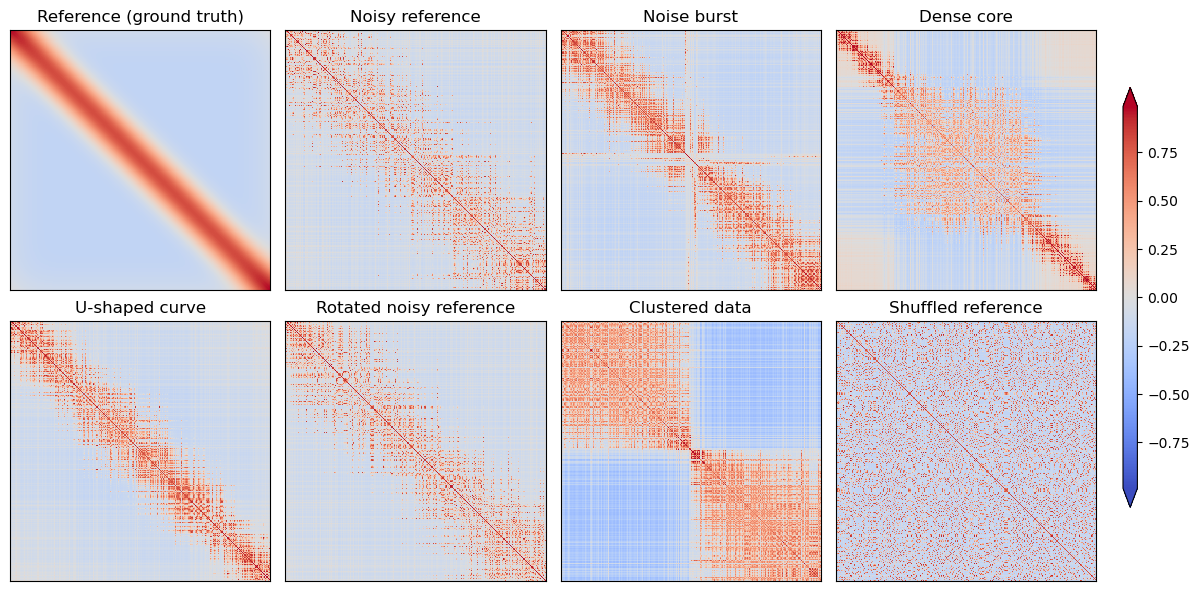

In [7]:
sigma_scott = scott_sigma(X)
print(f"Scott's rule: sigma = {sigma_scott:.2f}")

plot_centred_kernel_matrices(X, datasets, sigma=sigma_scott,
                             save_as='demo1_kernel_matrices.png')

**RBF kernel at Scott's width.** The reference gives a narrow band: each sample is similar to
its neighbours along the line. The noise of the noisy and rotated references breaks the band
into speckle, the burst shows as a thin cross, the dense core as a block in the middle, the
clusters as two blocks, and the shuffled order scatters the similarities. The U-shaped curve
keeps a band: locally, a bent line still looks like a line.

## Taylor diagrams and inner product types

`compute_taylor_diagrams` computes the statistics of all four diagrams for one kernel width
$\sigma$, normalized by the reference, so the reference point is at radius 1 and correlation 1.
It is called for two kernel widths:

* a **very wide kernel** (`max_sigma`), twice the largest distance in the data. In this case each kernel diagram reaches its wide-kernel limit, which for the kernel classic diagram is the classic diagram. Its markers are **circles**, as in the classic diagram;
* **Scott's rule**, the local width chosen above. Its markers are **squares**.


In [8]:
def compute_taylor_diagrams(X, datasets, sigma):
    """
    Statistics of the classic, kernel classic, kernel HSIC and kernel MMD Taylor diagrams of the
    candidates against the reference X, normalized by the reference, for the kernel width
    sigma. The classic diagram has no kernel and ignores sigma.

    Returns a dict: diagram type -> list of the results of ktd.TaylorEstimator ('std_Y',
    'corr', 'rmse', ...), one for each candidate.
    """
    values = {}
    for td_type in ('classic', 'kernel_classic', 'kernel_hsic', 'kernel_mmd'):
        estimator = ktd.TaylorEstimator(td_type, normalized=True, gamma=1. / (2. * sigma**2))
        values[td_type] = [estimator.compute(X, d['ts']) for d in datasets]
    return values

def draw_taylor_panel(fig, subplot, td_type, wide, local, datasets, legend=False):
    """
    One Taylor diagram of type td_type in the subplot of fig: the reference point, its circle,
    the grid and the RMSE contours, a transparent circle per candidate for the very wide kernel
    (wide) and a square for the kernel width of local, both from compute_taylor_diagrams. The
    classic diagram has no kernel, so it has only the circles. The reference point and the
    circles carry the legend labels; legend=True shows the legend beside the diagram.
    Returns the TaylorDiagramPlot.
    """
    title = {'classic': 'Classic', 'kernel_classic': 'Kernel classic',
             'kernel_hsic': 'Kernel HSIC', 'kernel_mmd': 'Kernel MMD'}[td_type]
    ref_range = {'classic': (0., 20), 'kernel_classic': (0., 20),
                 'kernel_hsic': (0., 30), 'kernel_mmd': (0., 30)}[td_type]
    taylor = TaylorDiagramPlot(ref_point=1., fig=fig, subplot=subplot, extend_angle=False,
                               ref_range=ref_range)
    taylor.add_reference_point(1., color="black", marker=".", markersize=7.5, linestyle="",
                               label="Reference (ground truth)")
    taylor.add_reference_line(1., color="black", linestyle="--", label="_")
    taylor.add_grid()
    taylor.add_contours(1., levels=3, colors="gray")
    taylor.polar_axes.clabel(taylor.contours, inline=1, fontsize=20, fmt="%.1f")

    for r, d in zip(wide[td_type], datasets):
        taylor.add_point(r['std_Y'], r['corr'], color=d['color'], label=d['name'],
                         marker='o', markersize=9, linestyle='', markerfacecolor='none',
                         markeredgewidth=1.2, alpha=1., zorder=2.5)
    if td_type != 'classic':
        for r, d in zip(local[td_type], datasets):
            taylor.add_point(r['std_Y'], r['corr'], color=d['color'], label=None,
                             marker='s', markersize=8, linestyle='', markerfacecolor='none',
                             markeredgewidth=1.2, alpha=1., zorder=2.5)
    taylor.graph_axes.set_title(title, fontsize=16)
    if legend:
        handles, labels = taylor.polar_axes.get_legend_handles_labels()
        taylor.graph_axes.legend(handles, labels, ncols=1, loc='upper right',
                                 bbox_to_anchor=(1.25, 1.07), fontsize=9)
    return taylor


def plot_taylor_diagram(wide, local, datasets, td_type):
    """One Taylor diagram of type td_type, from compute_taylor_diagrams for a very wide kernel
    (wide, circles) and for a kernel width (local, squares), with its legend."""
    fig = plt.figure(figsize=(8, 6))
    draw_taylor_panel(fig, 111, td_type, wide, local, datasets, legend=True)
    plt.show()

def max_sigma(A):
    """Kernel width of a very wide kernel: twice the largest pairwise distance of A. Every pair
    of points of A is then well within one kernel width (the kernel value is at least 0.88),
    so the kernel diagrams reach their wide-kernel limit."""
    return 2. * sklearn.metrics.pairwise_distances(A, metric='euclidean').max()

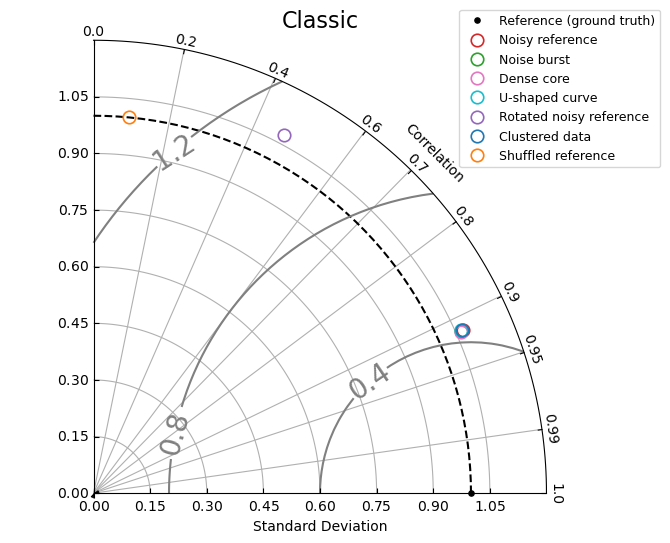

In [9]:
wide = compute_taylor_diagrams(X, datasets, max_sigma(X))      # circles: the wide-kernel limit
local = compute_taylor_diagrams(X, datasets, scott_sigma(X))   # squares: Scott's rule
plot_taylor_diagram(wide, local, datasets, 'classic')

**Classic.** The inner product of two datasets is the average, over the samples, of the dot
product between the paired points (the $i$-th point of the reference and the $i$-th point of the
candidate), each taken relative to the mean of its dataset. The noisy reference, the noise
burst, the dense core, the U-shaped curve and the clustered data fall on one point: the classic
diagram cannot tell them apart. The rotated line has half the correlation, and the shuffled
reference almost none.

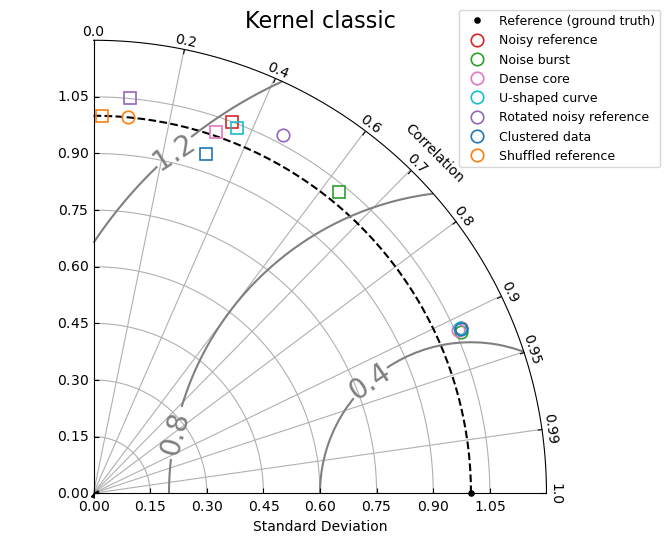

In [10]:
plot_taylor_diagram(wide, local, datasets, 'kernel_classic')

**Kernel classic.** The inner product of the datasets is the same average over paired points, but
of the dot product in the feature space, i.e. the kernel value of each pair, with each dataset
taken relative to its mean feature vector. The distance between two points then grows like their
error while the error is smaller than $\sigma$, and then stops growing: an error much larger than
$\sigma$ counts as a complete mismatch, however large it is. The noise burst, whose error is
concentrated in a few samples, now scores much better than the noisy reference, because its few
large errors count only as mismatches, and its other samples are less noisy. The dense core, the
U-shaped curve and the clustered data spread their errors over all samples, like the noisy
reference, and stay close to it.

The radius has a simple meaning here. Every point has length 1 in the feature space, so without
mean centering the standard deviation would be 1 for every dataset; centering subtracts the mean
feature vector, which gives $\text{std}^2 = 1 - \text{mean}(K)$, one minus the average similarity
of all pairs of samples. A compact dataset has many similar pairs and therefore a smaller radius:
the clustered data falls slightly inside the reference circle. With a very wide kernel (circles)
every error is much smaller than $\sigma$, and the diagram becomes the classic one.

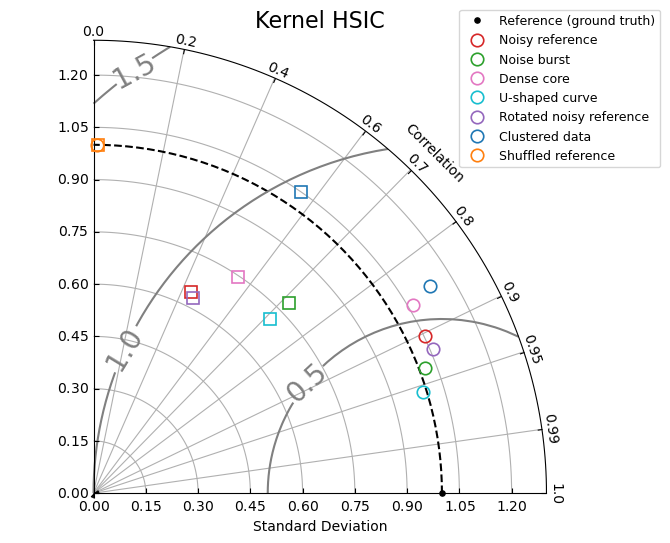

In [11]:
plot_taylor_diagram(wide, local, datasets, 'kernel_hsic')

**Kernel HSIC.** The inner product of two datasets is the average of the element-wise product of
their centered kernel matrices, which hold the dot products in the feature space between all
pairs of samples of each dataset. The correlation then measures how similar the two sets of
pairwise similarities are, the distance to the reference point is the norm of the difference
between the two matrices, and the radius is the norm of the candidate's matrix relative to the
reference.

* **With a very wide kernel (circles)** the matrices become the centered linear ones, and HSIC
  compares the pairwise dot products of the positions relative to the mean, so the five
  candidates that coincide in the classic diagram separate. A rotation does not change these dot
  products, so the rotated line matches well, unlike in the classic diagram. The correlation is
  lowered by noise and by a nonlinear relation in time. The less noisy noise burst and U-shaped
  curve match best, while the dense core and the clustered data, which redistribute the points
  along the line, match worse.
* **At Scott's width (squares)** the similarities are local, and HSIC compares neighborhoods,
  that is, whether samples close in the reference are also close in the candidate. Now the noise
  dominates, as it breaks the neighborhoods, while a nonlinear redistribution in time matters
  less, since a warped line still looks like a line locally.
* **The radius** tells how grouped a dataset is at the scale $\sigma$. It is largest for the
  clustered data and smallest for the noisiest datasets.
* At every width the rotated line stays with the noisy reference, and the shuffled reference is
  uncorrelated, because HSIC ignores orientation but not the order of the samples.

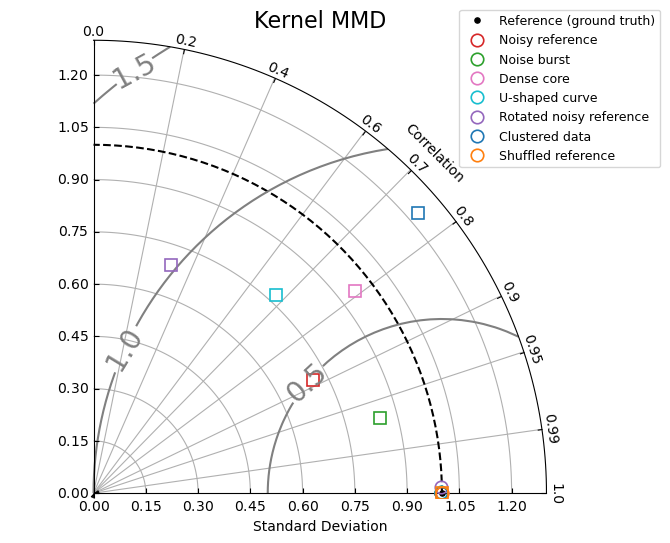

In [12]:
plot_taylor_diagram(wide, local, datasets, 'kernel_mmd')

**Kernel MMD.** The inner product of two datasets is the dot product of their mean feature
vectors, so the order of the samples plays no role. With the Gaussian kernel it has a simple
probabilistic meaning. Placing a Gaussian with a width proportional to $\sigma$ on every point of
a dataset and averaging gives a smoothed estimate of its distribution, a kernel density estimate,
and the inner product is proportional to the overlap of the two estimates. The diagram therefore
**compares the two distributions in the original space**, and the kernel width sets how finely.
A wide kernel sees only the overall position and spread of the points, while a narrower one also
resolves the shape of the distribution. The radius relates to entropy. A radius above 1 means a
more concentrated distribution than the reference, a radius below 1 a more spread one.

* **With a very wide kernel (circles)** MMD is not useful here. It sees only the overall position
  and spread, and all datasets are mean-centered with similar spreads, so every candidate
  collapses onto the reference point.
* **At Scott's width (squares)** MMD compares the distributions in detail. The shuffled reference
  coincides with the reference point, as it is the same set of points. The rotated line, the
  U-shaped curve, the clustered data and the dense core move away, because their points occupy a
  different region or are distributed differently along the line. The noise burst stays closest,
  as most of its points lie near the line. The clustered data, more concentrated than the line,
  has a radius above 1, and the noisy datasets, whose noise spreads the points, a radius below 1.

## All diagrams together

Each diagram separates different candidates, because each asks a different question: do the
samples match one by one (classic, kernel classic), do the datasets have the same structure
(HSIC), or the same distribution (MMD)?

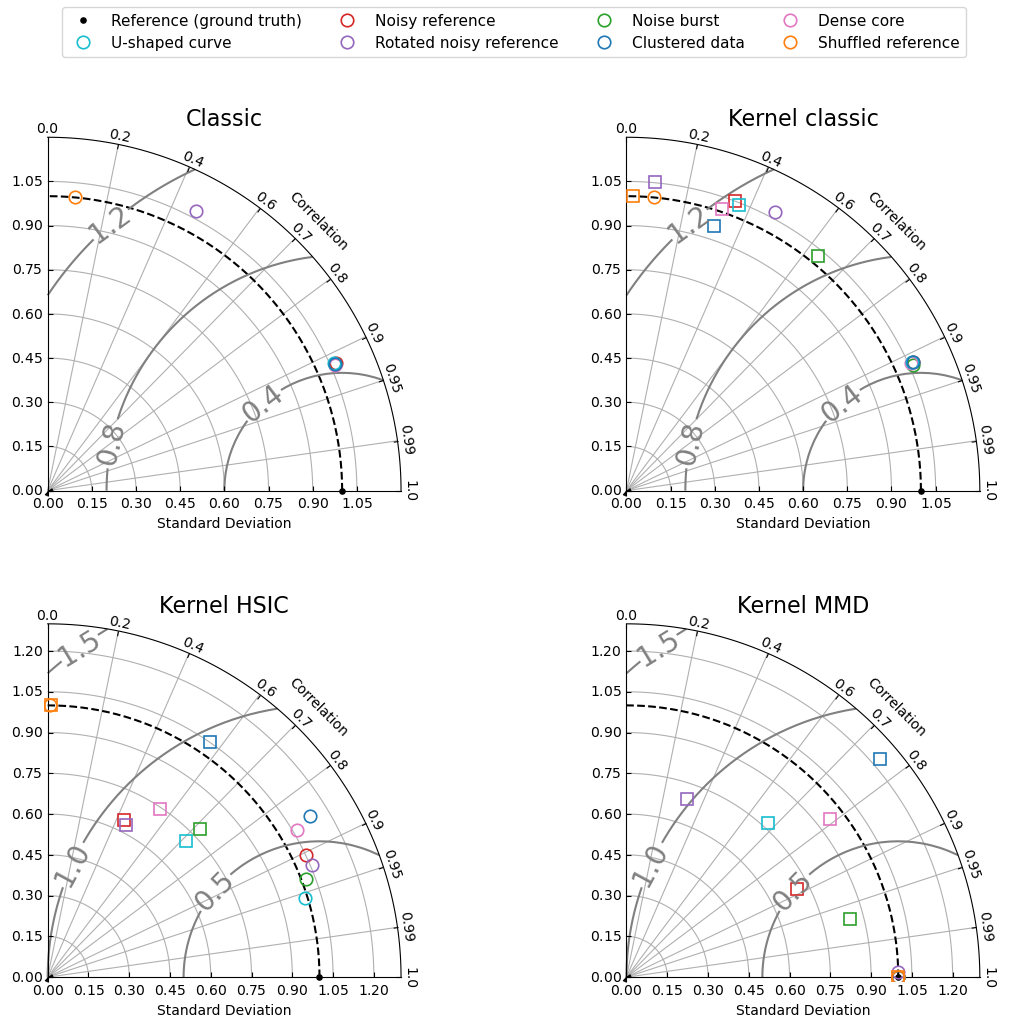

In [13]:
def plot_taylor_diagrams(wide, local, datasets, save_as=None):
    """The four Taylor diagrams, from compute_taylor_diagrams for a very wide kernel (wide,
    circles) and for a kernel width (local, squares), in a 2x2 layout with a common legend."""
    fig = plt.figure(figsize=(13, 11))
    for i, td_type in enumerate(wide):
        taylor = draw_taylor_panel(fig, 221 + i, td_type, wide, local, datasets)

    # Common legend in two rows, read row by row (matplotlib fills it column by column)
    handles, labels = taylor.polar_axes.get_legend_handles_labels()
    ncols = int(np.ceil(len(handles) / 2))
    order = [r * ncols + c for c in range(ncols) for r in range(2)
             if r * ncols + c < len(handles)]
    fig.legend([handles[k] for k in order], [labels[k] for k in order], loc='upper center',
               ncols=ncols, fontsize=11)
    fig.subplots_adjust(hspace=0.35, wspace=0.35)
    if save_as:
        fig.savefig(save_as, dpi=150, bbox_inches='tight', transparent=True)
    plt.show()

plot_taylor_diagrams(wide, local, datasets, save_as='demo1_all.png')

## Choosing the kernel width, and scanning it

Two common rules give very different widths: **Scott's rule** gives a local scale, close to the
noise level here, and the **median trick**, the median distance between the points of the
reference, a global one, the size of the whole dataset. A scan runs over all widths, from the
distance to the 5th neighbour up to twice the size of the data.

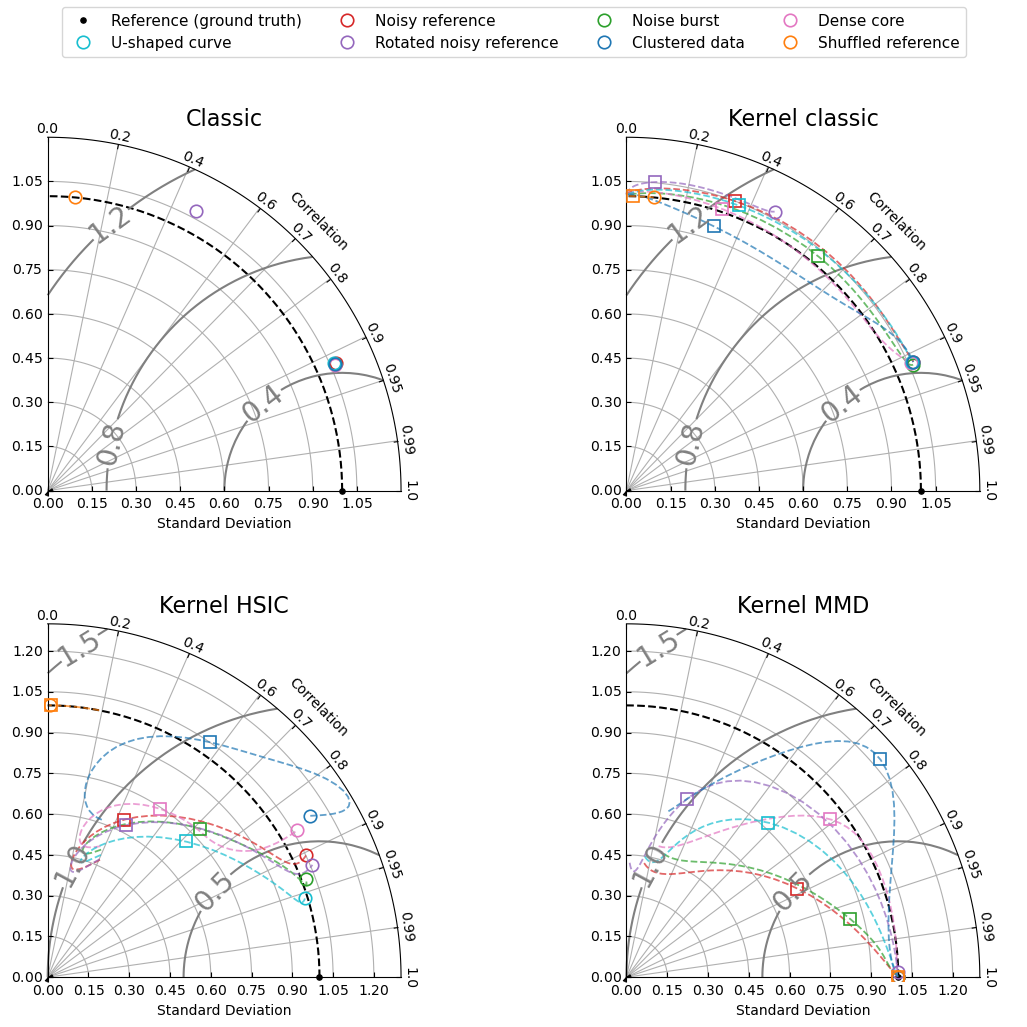

In [14]:
def min_sigma(A, n_neighbours=5):
    """Kernel width of a narrow kernel: the smallest distance from a point of A to its
    n_neighbours-th nearest neighbour. Below it no point of A has n_neighbours neighbours
    within one kernel width, and the kernel matrix of A is almost the identity."""
    dist = sklearn.metrics.pairwise_distances(A, metric='euclidean')
    # in a sorted row of distances, the first entry is the point itself
    return np.sort(dist, axis=1)[:, n_neighbours].min()


def compute_taylor_scans(X, datasets, steps_per_decade=20):
    """
    Taylor diagrams of the candidates against the reference X for kernel widths sigma from
    min_sigma(X) to max_sigma(X), spaced evenly on a log scale with steps_per_decade widths
    per decade.

    Returns the widths sigmas of the scan and, for each of them, the output of
    compute_taylor_diagrams.
    """
    sigma_min, sigma_max = min_sigma(X), max_sigma(X)
    n_steps = int(np.ceil(np.log10(sigma_max / sigma_min) * steps_per_decade)) + 1
    sigmas = np.geomspace(sigma_min, sigma_max, n_steps)
    return sigmas, [compute_taylor_diagrams(X, datasets, sigma) for sigma in sigmas]

def plot_taylor_scans(wide, local, scan, datasets, save_as=None):
    """
    The four Taylor diagrams as in plot_taylor_diagrams, with a dashed line per candidate
    through its values over the scan, the list of outputs of compute_taylor_diagrams returned
    by compute_taylor_scans. Only the kernel diagrams have lines: the classic diagram has no
    kernel.
    """
    fig = plt.figure(figsize=(13, 11))
    panels = {td_type: draw_taylor_panel(fig, 221 + i, td_type, wide, local, datasets)
              for i, td_type in enumerate(wide)}

    # The scan lines, read across the results of all kernel widths
    for td_type in ('kernel_classic', 'kernel_hsic', 'kernel_mmd'):
        for i, d in enumerate(datasets):
            std = np.array([values[td_type][i]['std_Y'] for values in scan])
            corr = np.array([values[td_type][i]['corr'] for values in scan])
            panels[td_type].add_point(std, corr, color=d['color'], label=None, marker='',
                                      linestyle='--', linewidth=1.3, alpha=0.7, zorder=2)

    # Common legend in two rows, read row by row (matplotlib fills it column by column)
    handles, labels = panels['classic'].polar_axes.get_legend_handles_labels()
    ncols = int(np.ceil(len(handles) / 2))
    order = [r * ncols + c for c in range(ncols) for r in range(2)
             if r * ncols + c < len(handles)]
    fig.legend([handles[k] for k in order], [labels[k] for k in order], loc='upper center',
               ncols=ncols, fontsize=11)
    fig.subplots_adjust(hspace=0.35, wspace=0.35)
    if save_as:
        fig.savefig(save_as, dpi=150, bbox_inches='tight', transparent=True)
    plt.show()

sigmas, scan = compute_taylor_scans(X, datasets)
plot_taylor_scans(wide, local, scan, datasets, save_as='demo1_all_scan.png')


`scan_values` computes the values of one diagram for all widths of a scan:

* The candidates separate most between $\sigma$ around Scott's width.
* At small widths every pair of points looks different; at very large widths the kernel
  diagrams lose their extra information (kernel classic becomes the classic diagram, MMD
  collapses).
* At every width the rotated line stays with the noisy reference in the HSIC diagram, and the
  shuffled reference coincides with the reference point in the MMD diagram.

## Recommendation: a local and a global kernel width

The diagrams answer different questions at different scales, so a single width can hide
differences. Besides the classic diagram, inspect the kernel diagrams at **at least two widths**, e.g. Scott's rule for the local structure and the median trick for the global one.

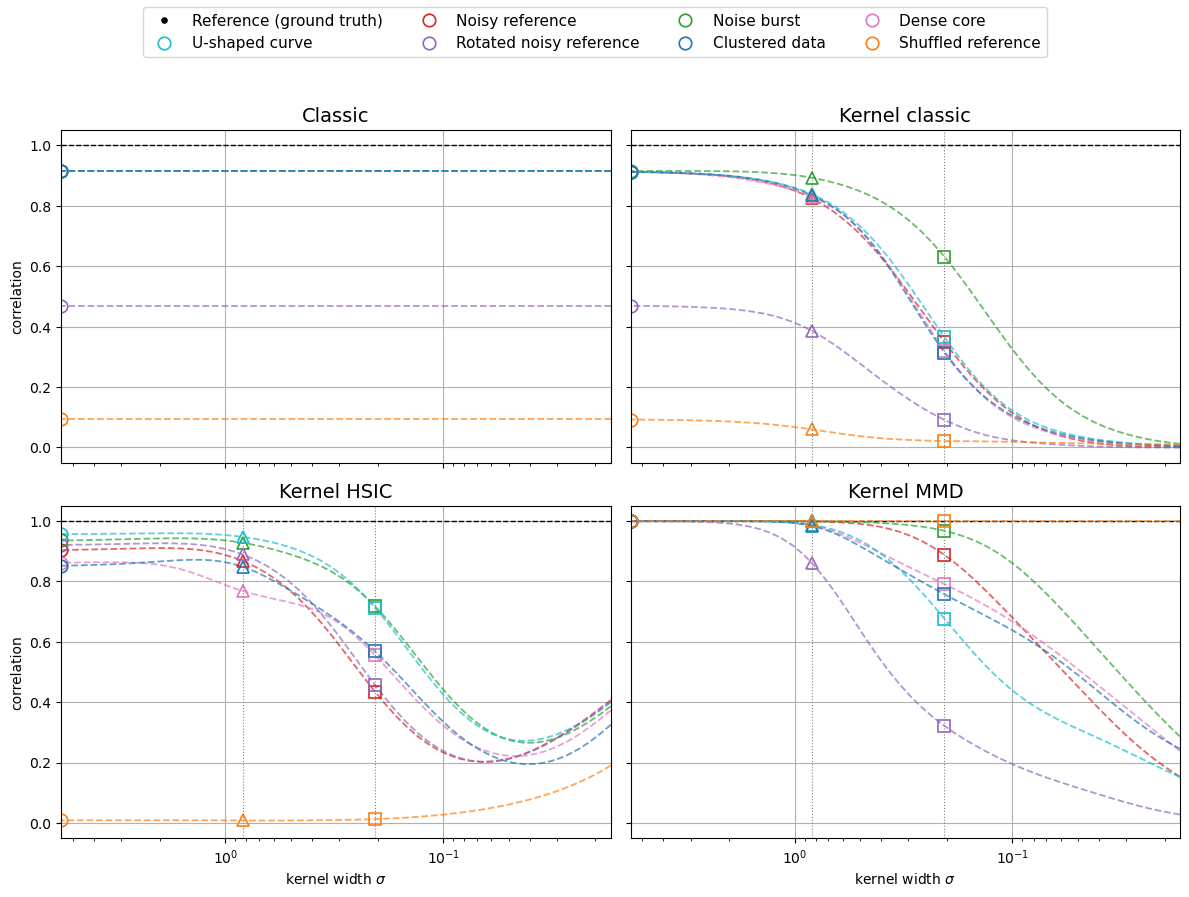

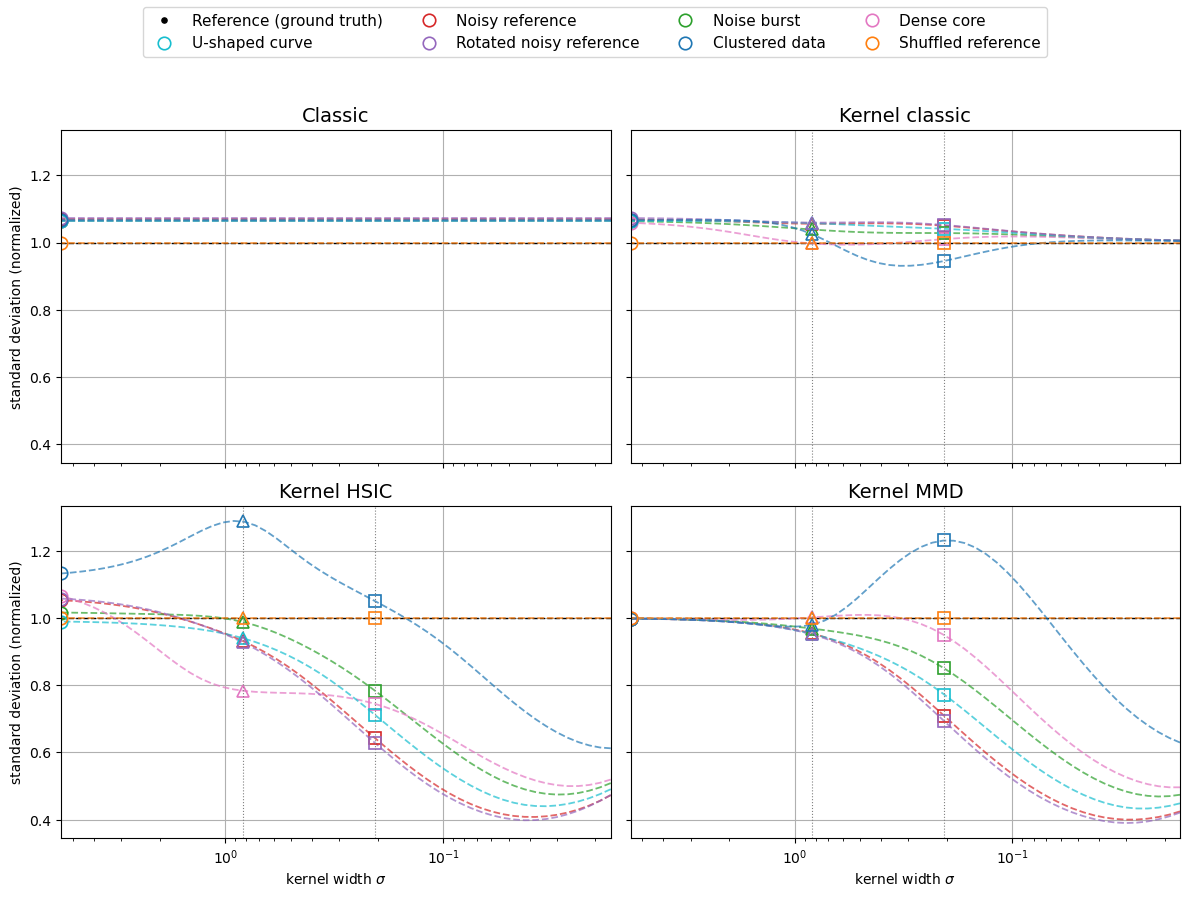

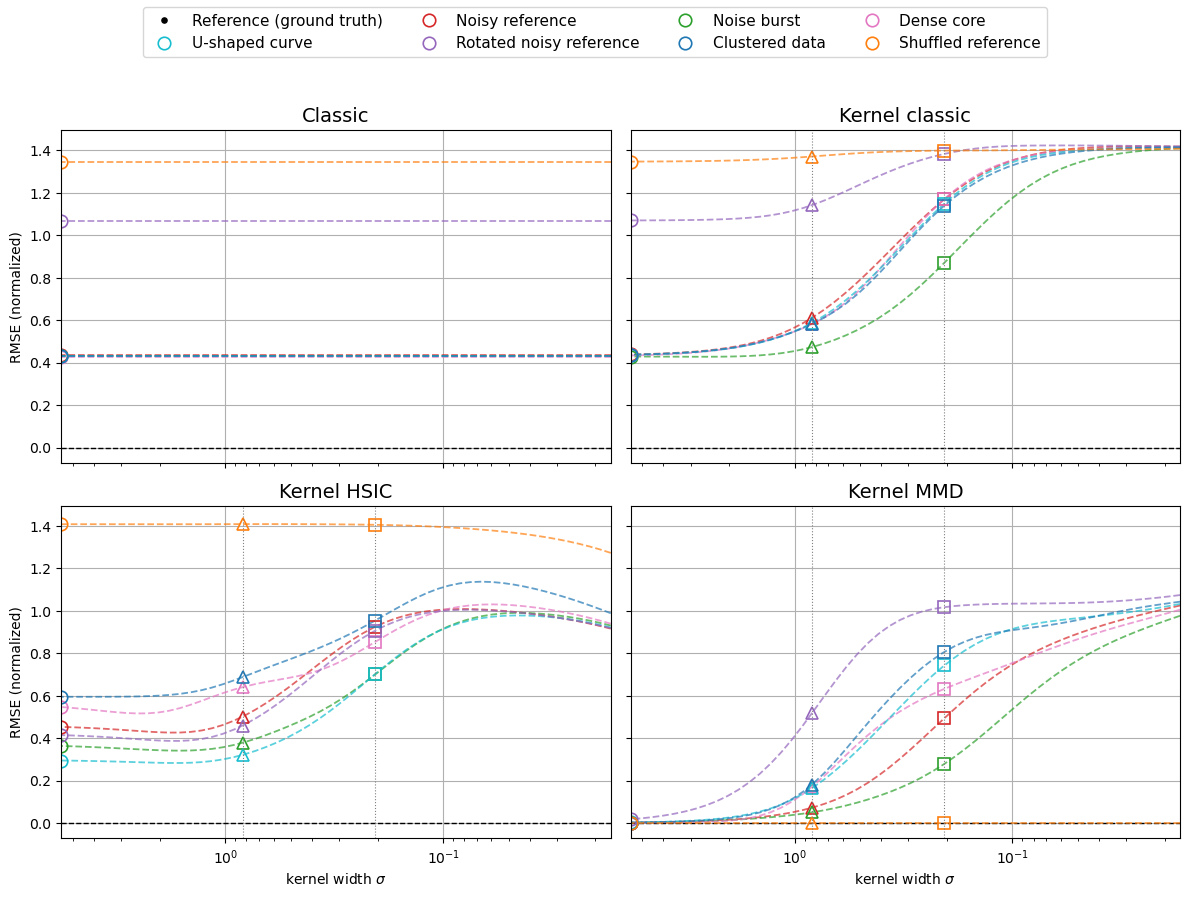

In [15]:
def median_sigma(A):
    """Median pairwise distance of A (median trick for the kernel width)."""
    dist = sklearn.metrics.pairwise_distances(A, metric='euclidean')
    return np.median(dist[dist > 0])

def plot_vs_sigma(sigmas, scan, marked, datasets, save_as=None):
    """
    The correlation, the standard deviation and the RMSE of the four Taylor diagrams against
    the kernel width sigma, with large widths on the left: three figures with the panels of the
    2x2 Taylor figure. Nothing is computed here.

    sigmas, scan: the output of compute_taylor_scans
    marked: list of (sigma, output of compute_taylor_diagrams), drawn as transparent markers:
            a circle for the first (the very wide kernel), then a square and a triangle, with a
            dotted vertical line at each of these. The classic diagram does not depend on
            sigma: its lines are constant, with the circle only.
    save_as: file name template whose {} is replaced by 'corr', 'std' and 'rmse'
    """
    titles = {'classic': 'Classic', 'kernel_classic': 'Kernel classic',
              'kernel_hsic': 'Kernel HSIC', 'kernel_mmd': 'Kernel MMD'}
    shapes = (('o', 9), ('s', 8), ('^', 9))
    quantities = (('corr', 'correlation', 1., 'corr'),
                  ('std_Y', 'standard deviation (normalized)', 1., 'std'),
                  ('rmse', 'RMSE (normalized)', 0., 'rmse'))

    # Legend entries: the reference point and a transparent circle for each candidate
    handles = [Line2D([], [], marker='.', color='black', linestyle='', markersize=7.5,
                      label='Reference (ground truth)')]
    handles += [Line2D([], [], marker='o', markersize=9, markerfacecolor='none',
                       markeredgecolor=d['color'], markeredgewidth=1.2, linestyle='',
                       label=d['name']) for d in datasets]
    ncols = int(np.ceil(len(handles) / 2))          # two rows, read row by row
    order = [r * ncols + c for c in range(ncols) for r in range(2)
             if r * ncols + c < len(handles)]

    for key, label, reference_value, file_key in quantities:
        fig, axs = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
        for ax, (td_type, title) in zip(axs.flatten(), titles.items()):
            ax.axhline(reference_value, color='black', linestyle='--', linewidth=1)
            for i, d in enumerate(datasets):
                ax.plot(sigmas, [values[td_type][i][key] for values in scan], color=d['color'],
                        linestyle='--', linewidth=1.3, alpha=0.7)
            marks = marked[:1] if td_type == 'classic' else marked
            for (sigma, values), (marker, size) in zip(marks, shapes):
                for r, d in zip(values[td_type], datasets):
                    ax.plot(sigma, r[key], linestyle='', marker=marker, markersize=size,
                            markerfacecolor='none', markeredgecolor=d['color'],
                            markeredgewidth=1.2)
            for sigma, _ in marks[1:]:
                ax.axvline(sigma, color='gray', linestyle=':', linewidth=0.8)
            ax.set_xscale('log')
            ax.set_xlim(sigmas[-1], sigmas[0])      # large widths on the left
            ax.set_title(title, fontsize=14)
            ax.grid(True)
        for ax in axs[:, 0]:
            ax.set_ylabel(label)
        for ax in axs[1, :]:
            ax.set_xlabel(r'kernel width $\sigma$')
        fig.legend(handles=[handles[k] for k in order], loc='upper center', ncols=ncols,
                   fontsize=11)
        fig.tight_layout(rect=(0., 0., 1., 0.9))
        if save_as:
            fig.savefig(save_as.format(file_key), dpi=150, bbox_inches='tight',
                        transparent=True)
        plt.show()

median = compute_taylor_diagrams(X, datasets, median_sigma(X))
marked = [(max_sigma(X), wide), (scott_sigma(X), local), (median_sigma(X), median)]
plot_vs_sigma(sigmas, scan, marked, datasets, save_as='demo1_vs_sigma_{}.png')

The same scans, unfolded: correlation, standard deviation and RMSE against $\sigma$, with large
(global) widths on the left and small (local) widths on the right.

* **Correlation.** Read from left to right, the kernel looks at finer and finer scales. The
  kernel classic correlations fall as $\sigma$ decreases, the noise burst last. In the MMD
  panel, each candidate leaves correlation 1 at the scale where its distribution starts to
  differ from the reference: first the rotated line, then the dense core, the clusters and the
  U-shaped curve, and last the noisy data.
* **Standard deviation.** In the HSIC and MMD panels, at local widths, it sorts the candidates by
  how spread they are: lowest for the noisiest datasets, above 1 for the clusters.
* **RMSE.** It combines both: the candidates separate where the RMSE curves fan out.